# 03 — Feature Engineering (leakage-safe)

**Target (unchanged):** `is_delayed = 1` if `arr_delay >= 15` min. Flights without an observed
arrival delay are excluded (`cancelled_policy: exclude`), so features describe flights *with an
observed arrival-delay label*. Cancellations are not predicted.

**Decision time:** end of day D−1 (`decision_time.mode: d_minus_1`). A feature for a flight on
date D may use (a) the published schedule, including all of day D's scheduled flights, and
(b) outcomes of earlier flights that were **known before D**.

| Group | Module | Uses |
|---|---|---|
| Calendar / time | `features/calendar.py` | scheduled departure, calendar, US federal holidays |
| Flight / route + interactions | `features/schedule.py`, `features/route.py` | schedule, carrier, airports |
| Congestion | `features/congestion.py` | counts on the **full raw schedule** (incl. unlabelled rows) |
| Historical | `features/historical.py` | outcomes known on dates D−w … D−1 only |

Learned transformations (rare/unseen category collapsing and numeric imputation) live in
`features/encoding.py` and are fitted on the **train split only**. The whole pipeline is
`features/build.py`; `scripts/build_features.py` writes the outputs to `data/processed/`.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repo root (folder containing pyproject.toml) so the notebook runs from anywhere.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from flight_delay.config import load_config  # noqa: E402

cfg = load_config(ROOT / "configs" / "config.yaml")
RAW_PATH = ROOT / cfg["paths"]["raw"]
THRESHOLD = cfg["target"]["threshold_minutes"]
POLICY = cfg["target"]["cancelled_policy"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Plot style: one accent hue, neutral ink, recessive grid.
ACCENT, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

print("raw file :", RAW_PATH.relative_to(ROOT))
print("sha256   :", hashlib.sha256(RAW_PATH.read_bytes()).hexdigest())
print(f"target   : arr_delay >= {THRESHOLD} min | missing-label policy: {POLICY}")

raw file : data/raw/flights.csv
sha256   : 8bdc6abbf07ac0cbb1036bc14a787cab3eea616be46c31899d2d8048963b08aa
target   : arr_delay >= 15 min | missing-label policy: exclude


## 1. Build the feature table

In [2]:
from flight_delay.data.load import load_raw
from flight_delay.features.build import (CATEGORICAL, build_feature_table, encode_splits,
                                         feature_groups, numeric_features)

raw = load_raw(RAW_PATH)
table = build_feature_table(raw, cfg)
FEATURES = numeric_features(cfg) + CATEGORICAL
print(f"raw rows: {len(raw):,} -> labelled rows with features: {len(table):,}")
print(f"features: {len(FEATURES)} ({len(numeric_features(cfg))} numeric, {len(CATEGORICAL)} categorical)")

per_split = table.groupby("split", observed=True).agg(
    n=("is_delayed", "size"), positive_rate=("is_delayed", "mean"),
    first_date=("date", "min"), last_date=("date", "max"))
per_split.loc[["train", "valid", "test"]].round(4)

raw rows: 336,776 -> labelled rows with features: 327,346
features: 59 (49 numeric, 10 categorical)


,n,positive_rate,first_date,last_date
split,,,,
train,217727,0.2637,2013-01-01,2013-08-31
valid,55628,0.1570,2013-09-01,2013-10-31
test,53991,0.2583,2013-11-01,2013-12-31


In [3]:
groups = feature_groups(cfg)
pd.DataFrame({"n_features": {g: len(c) for g, c in groups.items()},
              "examples": {g: ", ".join(c[:6]) + (" …" if len(c) > 6 else "") for g, c in groups.items()}})

,n_features,examples
calendar,10,"sched_dep_hour_frac, dow, is_weekend, is_holid..."
schedule_route,6,"sched_dep_min, sched_arr_min, sched_block_min,..."
categorical,10,"carrier, origin, dest, route, dep_bucket, carr..."
congestion,4,"sched_dep_origin_hour, sched_dep_origin_day, s..."
historical,29,"hist_global_all_rate, hist_carrier_1d_rate, hi..."


## 2. Leakage checks

1. **Column allow-list:** only named features are kept, and none is post-departure or derived
   from the target of the same flight.
2. **Future-record invariance:** rebuilding the table from data truncated at a cutoff date must
   give identical features for every flight up to and including that date.
3. **Strictly-earlier history:** on date D the global history count must equal the number of
   flights whose outcome was known before D.

In [4]:
from flight_delay.data.clean import build_labelled_frame
from flight_delay.features.historical import outcome_known_date
from flight_delay.features.leakage import POST_DEPARTURE_COLUMNS, assert_no_leakage

assert_no_leakage(FEATURES)
banned = POST_DEPARTURE_COLUMNS | {"is_delayed", "flight_status", "tailnum", "id"}
print("banned columns among features:", sorted(banned & set(FEATURES)) or "none")

banned columns among features: none


In [5]:
results = []
for cutoff in pd.to_datetime(["2013-03-31", "2013-08-31", "2013-10-31"]):
    trunc = build_feature_table(raw[raw["date"] <= cutoff], cfg).set_index("id")[FEATURES]
    full = table.set_index("id").loc[trunc.index, FEATURES]
    num = numeric_features(cfg)
    max_diff = (full[num] - trunc[num]).abs().max().max()
    cat_equal = all((full[c].astype(str) == trunc[c].astype(str)).all() for c in CATEGORICAL)
    results.append({"cutoff": cutoff.date(), "rows_compared": len(trunc),
                    "max_abs_numeric_diff": max_diff, "categoricals_identical": cat_equal})
pd.DataFrame(results)

,cutoff,rows_compared,max_abs_numeric_diff,categoricals_identical
0,2013-03-31,77911,0.0,True
1,2013-08-31,217727,0.0,True
2,2013-10-31,273355,0.0,True


In [6]:
from flight_delay.features.historical import add_historical_delay_rates

lab = build_labelled_frame(raw)
lab["is_delayed"] = lab["is_delayed"].astype(int)
known = outcome_known_date(lab)
# hist_global_all_n is an audit column, not a model feature: outcomes known before D
audit = add_historical_delay_rates(lab, ["carrier"], [1])
checks = []
for d in pd.to_datetime(["2013-01-02", "2013-04-15", "2013-09-01", "2013-12-31"]):
    used = audit.loc[audit["date"] == d, "hist_global_all_n"].unique()
    checks.append({"date": d.date(), "known_before_D": int((known < d).sum()),
                   "feature_value": used.tolist()})
display(pd.DataFrame(checks))

late = (known > lab["date"])
print(f"labelled flights whose outcome is known only on a later calendar date: {late.sum():,} "
      f"({late.mean():.2%}) — these enter history one day later than their flight date")

,date,known_before_D,feature_value
0,2013-01-02,733,[733.0]
1,2013-04-15,90693,[90693.0]
2,2013-09-01,217670,[217670.0]
3,2013-12-31,326469,[326469.0]


labelled flights whose outcome is known only on a later calendar date: 34,780 (10.62%) — these enter history one day later than their flight date


## 3. Congestion from the full raw schedule

In [7]:
labelled_only = (build_labelled_frame(raw).groupby(["origin", "date", "hour"])["id"]
                 .transform("size"))
cmp = table.set_index("id")["sched_dep_origin_hour"].to_frame("full_schedule").join(
    build_labelled_frame(raw).assign(labelled_only=labelled_only).set_index("id")["labelled_only"])
print("rows where the full-schedule count exceeds the labelled-only count:",
      f"{(cmp['full_schedule'] > cmp['labelled_only']).sum():,} of {len(cmp):,}")
print("rows where it is smaller (should be 0):", int((cmp["full_schedule"] < cmp["labelled_only"]).sum()))
table[["sched_dep_origin_hour", "sched_dep_origin_day", "sched_dep_carrier_origin_day",
       "sched_dep_origin_hour_share"]].describe().T.round(2)

rows where the full-schedule count exceeds the labelled-only count: 80,649 of 327,346
rows where it is smaller (should be 0): 0


,count,mean,std,min,25%,50%,75%,max
sched_dep_origin_hour,327346.0,20.50,5.93,1.0,17.00,21.00,24.00,38.00
sched_dep_origin_day,327346.0,312.64,36.58,171.0,297.00,313.00,340.00,377.00
sched_dep_carrier_origin_day,327346.0,69.42,46.22,1.0,29.00,56.00,121.00,147.00
sched_dep_origin_hour_share,327346.0,0.07,0.02,0.0,0.06,0.07,0.08,0.14


## 4. History coverage (insufficient / unseen history)

In [8]:
rows = []
for key in ["carrier", "route", "origin", "dest"]:
    for w in [f"{x}d" for x in cfg["features"]["history_windows_days"]]:
        col = f"hist_{key}_{w}_n"
        for s in ["train", "valid", "test"]:
            m = table["split"] == s
            rows.append({"key": key, "window": w, "split": s,
                         "share_with_no_history": (table.loc[m, col] == 0).mean()})
cov = pd.DataFrame(rows).pivot_table(index=["key", "window"], columns="split",
                                    values="share_with_no_history")[["train", "valid", "test"]]
display(cov.map("{:.2%}".format))
print("rows with no history at all (first date, rates NaN before imputation):",
      int(table["hist_global_all_rate"].isna().sum()))

split           train  valid   test
key     window                     
carrier 1d      0.42%  0.04%  0.04%
        28d     0.38%  0.00%  0.00%
        7d      0.38%  0.00%  0.00%
dest    1d      0.87%  0.38%  0.44%
        28d     0.40%  0.01%  0.02%
        7d      0.41%  0.01%  0.03%
origin  1d      0.38%  0.00%  0.00%
        28d     0.38%  0.00%  0.00%
        7d      0.38%  0.00%  0.00%
route   1d      1.45%  1.08%  1.38%
        28d     0.42%  0.03%  0.05%
        7d      0.44%  0.04%  0.08%

rows with no history at all (first date, rates NaN before imputation): 831


With no history for a key, the smoothed rate falls back to the global past rate. On the first
date (no past data at all), it is NaN and is imputed with the **train** median by the encoder.

## 5. Train-only encoding

In [9]:
splits, encoder = encode_splits(table, cfg)
enc_rows = []
for col in CATEGORICAL:
    cats = encoder.categories_[col]
    raw_levels = table.loc[table["split"] == "train", col].nunique()
    r = {"column": col, "train_levels": raw_levels, "kept": len(cats) - 1}
    for s, frame in splits.items():
        r[f"{s}_other_%"] = round(100 * (frame[col] == "__OTHER__").mean(), 2)
    enc_rows.append(r)
display(pd.DataFrame(enc_rows))
print("NaNs after encoding:", {s: int(f[FEATURES].isna().sum().sum()) for s, f in splits.items()})
print("category lists identical across splits:",
      all(list(splits["train"][c].cat.categories) == list(splits["test"][c].cat.categories)
          for c in CATEGORICAL))

,column,train_levels,kept,train_other_%,valid_other_%,test_other_%
0,carrier,16,15,0.00,0.03,0.01
1,origin,3,3,0.00,0.00,0.00
2,dest,102,93,0.06,0.14,0.17
3,route,218,189,0.23,1.30,1.20
4,dep_bucket,5,5,0.00,0.00,0.00
5,carrier_origin,35,33,0.00,0.03,0.01
6,carrier_dest,287,242,0.19,0.83,1.45
7,carrier_route,390,311,0.45,2.57,3.33
8,origin_dep_bucket,15,14,0.01,0.00,0.12
9,carrier_dep_bucket,61,53,0.05,0.12,0.14


NaNs after encoding: {'train': 0, 'valid': 0, 'test': 0}
category lists identical across splits: True


## 6. Descriptive signal (train split only)

Single-feature ROC AUC of each numeric feature against the target, computed on the **train
split only**, so no validation or test labels are consulted. This is descriptive screening, not
model selection; values are shown as max(AUC, 1−AUC) so direction does not matter.

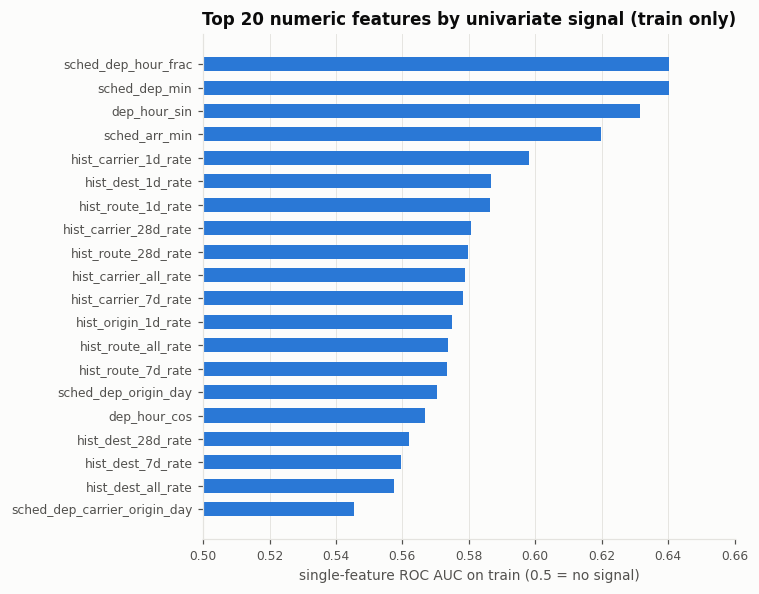

,max,median,size
group,,,
calendar,0.640,0.527,10
congestion,0.571,0.537,4
historical,0.598,0.533,29
schedule_route,0.640,0.522,6


In [10]:
from sklearn.metrics import roc_auc_score

tr = splits["train"]
auc = pd.Series({c: roc_auc_score(tr["is_delayed"], tr[c]) for c in numeric_features(cfg)})
auc = np.maximum(auc, 1 - auc).sort_values()
top = auc.tail(20)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values - 0.5, left=0.5, color=ACCENT, height=0.6)
ax.set_xlim(0.5, top.max() + 0.02)
ax.set_xlabel("single-feature ROC AUC on train (0.5 = no signal)")
ax.set_title("Top 20 numeric features by univariate signal (train only)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
group_of = {c: g for g, cols in groups.items() for c in cols}
auc.to_frame("auc").assign(group=lambda d: d.index.map(group_of)).groupby("group")["auc"].agg(["max", "median", "size"]).round(3)

In [11]:
# Redundancy among numeric features (train): highly correlated pairs
corr = tr[numeric_features(cfg)].corr("spearman").abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("abs_spearman").sort_values(ascending=False))
print(f"pairs with |rho| > 0.95: {(pairs > 0.95).sum()} of {len(pairs)}")
pairs.head(10).round(3).to_frame()

pairs with |rho| > 0.95: 8 of 1176


abs_spearman
sched_dep_hour_frac sched_dep_min              1.000
distance            log_distance               1.000
sched_block_min     log_distance               0.985
                    distance                   0.985
hist_dest_7d_n      hist_dest_28d_n            0.965
hist_dest_1d_n      hist_dest_7d_n             0.964
hist_route_7d_n     hist_route_28d_n           0.963
hist_route_1d_n     hist_route_7d_n            0.957
hist_carrier_7d_n   hist_carrier_28d_n         0.943
hist_dest_1d_n      hist_dest_28d_n            0.918

## A. Pre-training audit

Three checks before model training. Post-departure fields appear below **only** to validate
time handling, never as features. Feature comparisons use **train and validation rows only**;
the test split is not inspected.

### A1. Scheduled duration on a common time basis

Departure times are origin-local and arrival times are destination-local, with no arrival date.
`sched_block_min` converts both to UTC using each airport's IANA zone (vendored in
`features/airport_timezones.py`, from `airportsdata` 20250909) and resolves the arrival date.
Validation: with correct zones, actual gate-to-gate time minus `air_time` (taxi time) can never
be negative.

In [12]:
from flight_delay.data.load import hhmm_to_minutes
from flight_delay.features.airport_timezones import AIRPORT_TZ
from flight_delay.features.schedule import add_schedule_features
from flight_delay.features.timebase import arrival_utc, localize_to_utc

airports = set(raw["dest"]) | set(raw["origin"])
print("airports in data:", len(airports), "| missing a time zone:",
      sorted(airports - set(AIRPORT_TZ)) or "none")
lab_a = build_labelled_frame(raw)
dep_local = lab_a["sched_dep_dt"] + pd.to_timedelta(lab_a["dep_delay"], unit="m")
dep_u = localize_to_utc(dep_local, lab_a["origin"])
arr_u = arrival_utc(dep_u, dep_local.dt.normalize(), lab_a["arr_time"], lab_a["dest"])
taxi_tz = (arr_u - dep_u).dt.total_seconds() / 60 - lab_a["air_time"]
taxi_clock = (hhmm_to_minutes(lab_a["arr_time"]) - hhmm_to_minutes(lab_a["dep_time"])) % 1440 - lab_a["air_time"]
sched = add_schedule_features(raw)
clock = (hhmm_to_minutes(raw["sched_arr_time"]) - hhmm_to_minutes(raw["sched_dep_time"])) % 1440
pd.DataFrame({
    "local clock difference (old)": {"taxi < 0 (impossible)": f"{(taxi_clock < 0).mean():.2%}",
                                     "corr with distance": round(raw["distance"].corr(clock), 3)},
    "sched_block_min (UTC basis)": {"taxi < 0 (impossible)": f"{(taxi_tz < 0).mean():.2%}",
                                    "corr with distance": round(raw["distance"].corr(sched["sched_block_min"]), 3)},
})

airports in data: 107 | missing a time zone: none


,local clock difference (old),sched_block_min (UTC basis)
taxi < 0 (impossible),39.80%,0.00%
corr with distance,0.769,0.993


### A2. Validity at the decision time (end of D−1)

History: a past flight's outcome is counted from its **actual arrival in New York time + 30 min**.
The earlier estimate (departure + delay + air time + 120 min) ignored taxi times, which reach
235 min in this data.

In [13]:
from flight_delay.features.historical import outcome_known_date
from flight_delay.features.timebase import actual_arrival_ny

arr_ny = actual_arrival_ny(lab_a)
old_estimate = (lab_a["sched_dep_dt"] + pd.to_timedelta(lab_a["dep_delay"], unit="m")
                + pd.to_timedelta(lab_a["air_time"], unit="m") + pd.Timedelta(minutes=120)).dt.normalize()
new_known = outcome_known_date(lab_a)
print("max taxi time (min):", taxi_tz.max())
print("labels counted BEFORE their NY arrival date — old rule:", int((old_estimate < arr_ny.dt.normalize()).sum()),
      "| current rule:", int((new_known < arr_ny.dt.normalize()).sum()))
print(f"labels that enter history only on a later date than their flight date: {(new_known > lab_a['date']).mean():.2%}")

canc = raw.assign(cancelled=raw["dep_time"].isna())
print(f"congestion slots containing >=1 later-cancelled flight: "
      f"{canc.groupby(['origin', 'date', 'hour'])['cancelled'].transform('max').mean():.1%}")
canc.groupby("date")["cancelled"].agg(["sum", "mean"]).nlargest(3, "sum").round(3)

max taxi time (min): 235.0
labels counted BEFORE their NY arrival date — old rule: 23 | current rule: 0
labels that enter history only on a later date than their flight date: 10.62%
congestion slots containing >=1 later-cancelled flight: 22.7%


,sum,mean
date,,
2013-02-08,472,0.508
2013-02-09,393,0.575
2013-05-23,221,0.224


### A3. Month / day-of-year under the chronological split (train vs validation only)

Training covers January–August. Any month encoding, raw or cyclic, has to say something about
months it never saw.

In [14]:
from flight_delay.features.calendar import add_calendar_features

cal = add_calendar_features(table[["date"]].assign(sched_dep_dt=table["date"]))
cal["split"], cal["is_delayed"] = table["split"].values, table["is_delayed"].values
tr_c, va_c = cal[cal["split"] == "train"], cal[cal["split"] == "valid"]
rng = {c: f"{((va_c[c] < tr_c[c].min()) | (va_c[c] > tr_c[c].max())).mean():.0%}"
       for c in ["month", "day_of_year", "month_sin", "month_cos", "doy_sin", "doy_cos",
                 "dow", "days_from_holiday"]}
print("validation rows outside the training range:", rng)
print("train delay rate by month:", tr_c.groupby("month")["is_delayed"].mean().round(3).to_dict())
print("valid delay rate by month:", va_c.groupby("month")["is_delayed"].mean().round(3).to_dict())
print("train Spearman(month, target):", round(tr_c[["month", "is_delayed"]].corr("spearman").iloc[0, 1], 3))

va_t = table[table["split"] == "valid"]
wk = va_t.assign(week=va_t["date"].dt.isocalendar().week).groupby("week")[["hist_origin_28d_rate", "is_delayed"]].mean()
wk.round(3).T

validation rows outside the training range: {'month': '100%', 'day_of_year': '100%', 'month_sin': '100%', 'month_cos': '0%', 'doy_sin': '100%', 'doy_cos': '0%', 'dow': '0%', 'days_from_holiday': '0%'}
train delay rate by month: {1: 0.235, 2: 0.238, 3: 0.236, 4: 0.288, 5: 0.227, 6: 0.315, 7: 0.322, 8: 0.246}
valid delay rate by month: {9: 0.137, 10: 0.176}
train Spearman(month, target): 0.041


week,35,36,37,38,39,40,41,42,43,44
hist_origin_28d_rate,0.237,0.223,0.170,0.165,0.151,0.130,0.142,0.148,0.160,0.179
is_delayed,0.111,0.127,0.214,0.124,0.101,0.105,0.242,0.164,0.182,0.167


Raw month/day-of-year, and `month_sin`/`doy_sin`, are outside the training range for every
validation row. The cyclic pairs are also unseen combinations: September and October fall
nearest August in (sin, cos) space, so either encoding implies August-like risk (24.6%).
Validation actually shows 13.7% and 17.6%. With a weakly positive training trend, a linear
month term would extrapolate upward. The past-only 28-day origin rate tracks the shift instead
(about 0.24 → 0.13–0.18). **Decision:** month and day-of-year encodings are excluded. Day of
week, weekend and holiday-proximity features stay, since they lie within the training range.

## Findings (from the outputs above)

**Feature set:** 59 features (49 numeric, 10 categorical) for 327,346 labelled flights:
- 10 calendar/time features
- 6 schedule/route numerics
- 10 categoricals (carrier, airports, route and their crosses)
- 4 congestion counts
- 29 historical features

The target and split are unchanged: positive rate 26.37% train / 15.70% valid / 25.83% test, on the configured dates.

**Leakage safeguards (verified)**
1. No post-departure column, target-derived column, `tailnum` or `id` is a feature. The table is built from an explicit allow-list and checked with `assert_no_leakage`.
2. **Future-record invariance:** rebuilding from data truncated at 2013-03-31, 2013-08-31 and 2013-10-31 reproduces every earlier row's features exactly (max difference 0.0). Validation and test records cannot influence training features.
3. **Strictly earlier history:** on each audited date D, the history count equals the number of outcomes known before D (e.g. 90,693 on 2013-04-15).
4. **Outcome timing (audit A2):** a past flight's label is counted from its actual arrival in New York time + 30 min.
   - The previous estimate (departure + delay + air time + 120 min) counted **23** labels a day before the flight had actually landed. This was a verified, now-fixed leak: taxi times reach 235 min.
   - 10.62% of labelled flights enter history one day after their flight date.
5. **Train-only encoding:** rare/unseen category levels map to `__OTHER__`, and the 831 first-day NaNs get the training median.

**Audit results**
- **A1 — scheduled duration:**
  - The old local-clock difference was not a duration. With actual times, the same calculation implies negative taxi time for 39.8% of flights.
  - `sched_block_min` uses IANA time zones for all 107 airports and resolves the arrival date. It gives 0.00% negative taxi times and correlates 0.993 with distance.
  - It is nearly collinear with `distance` (ρ 0.985), and its univariate train AUC is only 0.523. It is kept as a correct schedule feature; for Logistic Regression, regularisation should handle the overlap.
- **A3 — unseen months:**
  - Raw month/day-of-year and `month_sin`/`doy_sin` are outside the training range for **100%** of validation rows.
  - Training seasonality maps September and October onto August (24.6%), but validation shows 13.7% and 17.6%.
  - All month and day-of-year encodings were removed. Day of week, weekend and holiday features stay (0% out of range). Seasonality is left to past-only history windows; the 28-day origin rate moves from 0.24 to 0.13–0.18 during validation.
  - The comparison used train and validation only, without fitting any model.

**Univariate signal (train only, descriptive):**
- Scheduled departure time is the strongest single feature (AUC 0.640).
- Next come recent carrier and destination delay rates (`hist_carrier_1d_rate` 0.598, `hist_dest_1d_rate` 0.587).
- Congestion reaches 0.571.

**Remaining redundancy:** 8 pairs with |ρ| > 0.95, e.g. `distance`/`log_distance`, `sched_dep_hour_frac`/`sched_dep_min`, `sched_block_min`/`distance`, adjacent history-window counts.

## Unresolved limitations
- **Schedule availability at D−1 cannot be verified.** The data holds the final schedule as operated or cancelled, with no publication or amendment timestamps. Schedule changes made close to departure, or flights missing from the file entirely, cannot be detected.
- **Congestion includes flights later cancelled** (22.7% of origin-hour slots contain one). Some of these cancellations, such as the 8–9 February 2013 blizzard (51–58% of flights cancelled), were probably announced before D−1. A planner at the cutoff would then have known the reduced schedule. The data has no cancellation-announcement times, so counts reflect the originally scheduled flights. This does not reveal any flight's own outcome.
- **Real-time outcome availability is assumed.** History windows assume flight outcomes are known within about 30 min of arrival, e.g. from an operational flight-status feed. Public BTS files are released monthly with a lag, so a system using only BTS downloads could not compute the 1/7/28-day windows. The 30-min reporting buffer is an assumption, not measured.
- **Time-zone data is external** (`airportsdata` 20250909, vendored for the 107 airports). It is validated against this data (no negative taxi times) but is not part of the original dataset.
- **Recent history is outside its training range for some validation rows** (e.g. `hist_origin_28d_rate` is below its training minimum for 23% of validation rows, because September–October were unusually punctual). This reflects a genuine regime change rather than a calendar artefact. Trees will treat it as the lowest training value.
- **Validation is unrepresentative:** its delay rate (15.7%) is far below train and test. Threshold and calibration choices made on validation should be interpreted with care.